Описание данных: две компонентны скорости (Vx, Vy), полученные из моделирования турбулентной струи в воде (несжимаемая среда). Снизу -- твердая стенка, сверху задается профиль вертикальной скорости в виде функции Гаусса. Справа и слева -- свободные границы.

Задание: необходимо прочитать данные двух компонент скорости из файлов. Выбрать 10 x 10 точек равномерно, и восстановить поля скоростей, включая в Loss-функцию отклонения от этих точек и невязку от уравнения непрерывности.

In [1]:
# импортировать необходимые библиотеки
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
import time
import torch
from torch import autograd
import torch.nn as nn
import torch.optim as optim
import tqdm
import zipfile

Загрузить в google collab zip-архив с данными. Распоковать данные.

In [2]:
!unzip /content/PINN_data.zip

Archive:  /content/PINN_data.zip
   creating: PINN_data/
  inflating: PINN_data/Vx.txt        
  inflating: PINN_data/Vy.txt        


Написать функцию для чтения файлов.

Входные аргументы функции: название файла (string)

Выходные данные: массив из N строк и 3 столбцов (np.array)

In [3]:
def readfile(filename:str):
    return np.loadtxt(filename)

Проверить, что функция возвращает правильные массивы.

Вывести размеры массива.

Построить точечный график с координатами точек.

In [4]:
Vx=readfile("/content/PINN_data/Vx.txt")
Vy=readfile("/content/PINN_data/Vy.txt")
print('Vx', Vx.shape, 'Vy', Vy.shape)

Vx (40210, 3) Vy (40210, 3)


Создать класс с двумя полями:
*   Vx
*   Vy

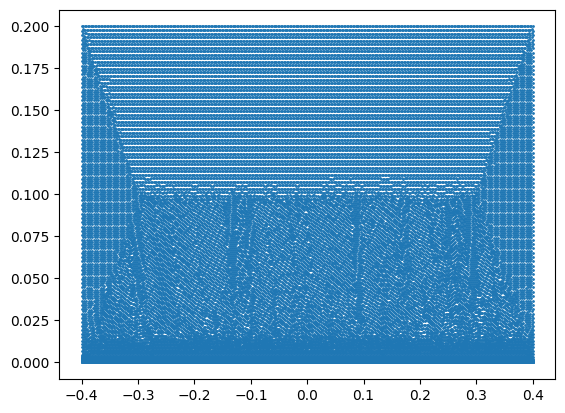

In [5]:
plt.scatter(Vx[:,0], Vx[:,1], s=1)

In [6]:
class velocity:
    def __init__(self, Vx=None, Vy=None):
        self.Vx = Vx
        self.Vy = Vy
velocityarray=velocity(Vx, Vy)
print(velocityarray.Vx)

[[-4.00000000e-01  1.50644288e-02 -2.02633237e+01]
 [-4.00000000e-01  1.71908668e-02 -2.00410235e+01]
 [-4.00000000e-01  4.20440232e-02 -1.56190330e+01]
 ...
 [ 4.00000000e-01  2.00000000e-01  0.00000000e+00]
 [ 4.00000000e-01  1.45621713e-01  4.91649946e-01]
 [ 4.00000000e-01  1.63747809e-01  1.61488364e-01]]


Создать функцию, которая будет аппроксимировать исходные данные на равномерную сетку.

In [7]:
gridx = np.linspace(-0.4, 0.4, 500)
gridy = np.linspace(0.0, 0.2, 300)
gridx, gridy = np.meshgrid(gridx, gridy)


In [8]:
def aproximaion(pointsx, pointsy,
                values, gridx, gridy):
   return griddata((pointsx, pointsy), values,
                   (gridx, gridy))



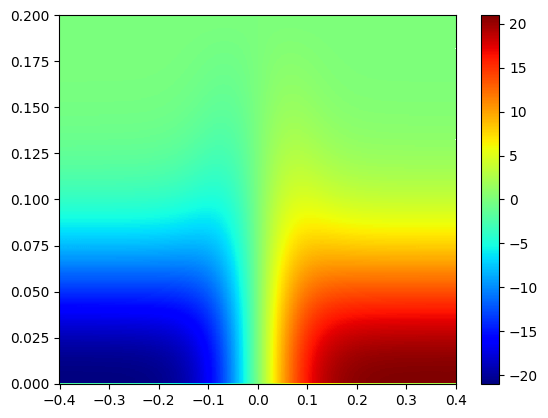

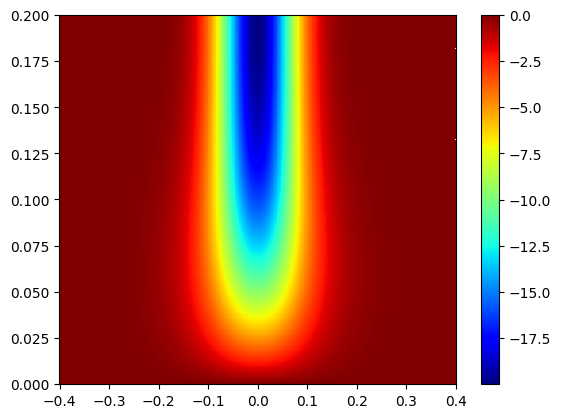

In [9]:
vxuniform=aproximaion(Vx[:,0], Vx[:,1], Vx[:,2],
                  gridx, gridy)
vyuniform=aproximaion(Vy[:,0], Vy[:,1], Vy[:,2],
                  gridx, gridy)

plt.pcolormesh(gridx, gridy, vxuniform,cmap='jet')
plt.colorbar()
plt.show()
plt.pcolormesh(gridx, gridy, vyuniform,cmap='jet')
plt.colorbar()
plt.show()




Написать простую нейросеть, использовать шаблон как здесь:

https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html

Но использовать nn.Tanh()

Проверить, что нейросеть задана правильно.

In [10]:
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_stack = nn.Sequential(
            nn.Linear(2, 20),
            nn.Tanh(),
            nn.Linear(20, 20),
            nn.Tanh(),
            nn.Linear(20, 20),
            nn.Tanh(),
            nn.Linear(20, 20),
            nn.Tanh(),
            nn.Linear(20, 2),

        )

    def forward(self, x):
        out = self.linear_stack(x)
        return out

Написать Loss функцию

In [11]:
tensor = torch.rand((100,2))
neuro = PINN()
out = neuro(tensor)
print(out.shape)

torch.Size([100, 2])


In [12]:
xy_np = np.column_stack([gridx.flatten(), gridy.flatten()]).astype(np.float32)
vx_np = vxuniform.flatten()[:, None].astype(np.float32)
vy_np = vyuniform.flatten()[:, None].astype(np.float32)

# удаление точек с NaN (возникают на границах при griddata)
mask = np.isfinite(vx_np.ravel()) & np.isfinite(vy_np.ravel())
xy_np = xy_np[mask]
vx_np = vx_np[mask]
vy_np = vy_np[mask]

xy_train = torch.from_numpy(xy_np)
vx_train = torch.from_numpy(vx_np)
vy_train = torch.from_numpy(vy_np)


Написать цикл обучения

https://docs.pytorch.org/tutorials/beginner/introyt/trainingyt.html#the-training-loop

In [14]:
class TrainParams:
    def __init__(self, numEpoch=80, xy=None, vx=None, vy=None):
        self.numEpoch = numEpoch
        self.xy = xy
        self.vx = vx
        self.vy = vy


def copyLoss(model, trp):
    pred = model(trp.xy)
    loss_x = torch.mean((pred[:, 0:1] - trp.vx) ** 2)
    loss_y = torch.mean((pred[:, 1:2] - trp.vy) ** 2)
    return loss_x, loss_y


def train(model, opt, trp):
    hist_loss_x = []
    hist_loss_y = []
    pbar = tqdm.tqdm(range(trp.numEpoch), desc="Training Progress")
    t0 = time.time()

    for step in pbar:
        def closure():
            opt.zero_grad()
            loss_x, loss_y = copyLoss(model, trp)
            loss = loss_x + loss_y          # общая потеря для обратного прохода
            loss.backward()
            return loss

        current_loss = float(opt.step(closure).detach())


        with torch.no_grad():
            lx, ly = copyLoss(model, trp)
        hist_loss_x.append(float(lx))
        hist_loss_y.append(float(ly))

        if step % 2 == 0:
            pbar.set_description(
                "Step: %d | Loss_x: %.6e | Loss_y: %.6e" % (step, hist_loss_x[-1], hist_loss_y[-1])
            )

    torch.save(model.state_dict(), "pinn_model")
    print(f"Обучение заняло {time.time() - t0:.1f} с. Веса сохранены в 'pinn_model'.")
    return hist_loss_x, hist_loss_y



trp = TrainParams(numEpoch=10, xy=xy_train, vx=vx_train, vy=vy_train)
opt = torch.optim.LBFGS(
    neuro.parameters(),
    lr=0.5,
    max_iter=20,
    history_size=50,
    line_search_fn="strong_wolfe",
)

hist_lossx, hist_lossy = train(neuro, opt, trp)
print(f"Итоговый Lossx = {hist_lossx[-1]:.6e}")
print(f"Итоговый Lossy = {hist_lossy[-1]:.6e}")


Step: 8 | Loss_x: 4.364178e-01 | Loss_y: 2.822301e-02: 100%|██████████| 10/10 [00:33<00:00,  3.33s/it]

Обучение заняло 33.3 с. Веса сохранены в 'pinn_model'.
Итоговый Lossx = 3.840356e-01
Итоговый Lossy = 3.104304e-02


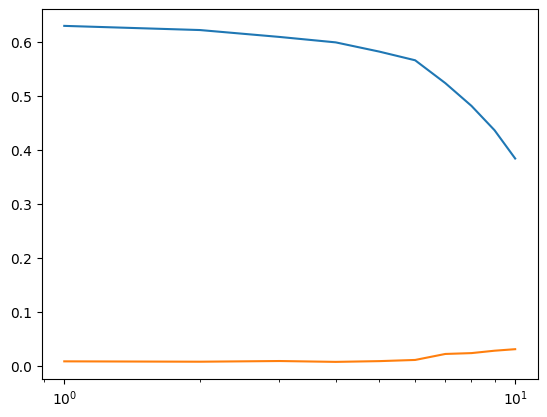

In [15]:
fig=plt.figure()
ax=plt.axes()
ax.plot(np.arange(1, len(hist_lossx) + 1), hist_lossx)
ax.plot(np.arange(1, len(hist_lossy) + 1), hist_lossy)
ax.set_xscale("log")

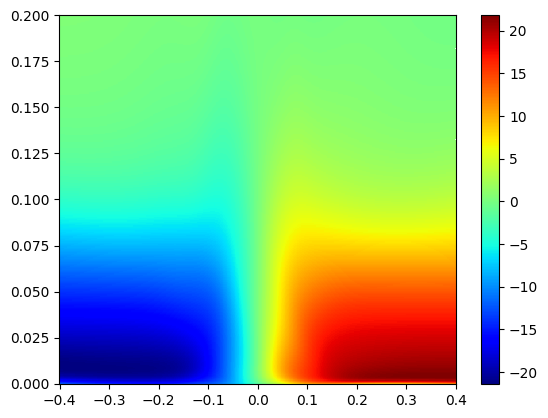

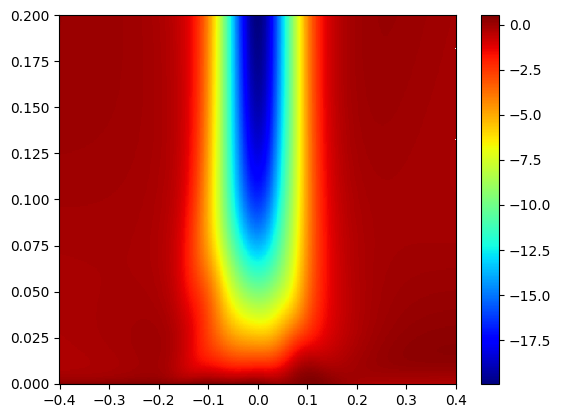

In [16]:
neuro.eval()
with torch.no_grad():
    pred = neuro(xy_train).cpu().numpy()
    vx_pred = np.full(gridx.shape, np.nan, dtype=np.float32)
    vy_pred = np.full(gridx.shape, np.nan, dtype=np.float32)
    # восстановить полную сетку с учётом ранее отфильтрованных точек
    flat_mask = np.isfinite(vxuniform.ravel()) & np.isfinite(vyuniform.ravel())
    vx_pred.ravel()[flat_mask] = pred[:, 0]
    vy_pred.ravel()[flat_mask] = pred[:, 1]
plt.pcolormesh(gridx, gridy, vx_pred, cmap='jet')
plt.colorbar()
plt.show()
plt.pcolormesh(gridx, gridy, vy_pred, cmap='jet')
plt.colorbar()
plt.show()
